# Exploratory Data Analysis

Every other page in this section fits a model. This one is about the step before
that, and it follows the
[NIST/SEMATECH e-Handbook of Statistical Methods](https://www.itl.nist.gov/div898/handbook/eda/eda.htm),
chapter 1 — the most careful free treatment of the subject there is.

The handbook is emphatic about what EDA is not:

> *"EDA is not a mere collection of techniques; EDA is a philosophy as to how we
> dissect a data set."*

The distinction it draws with classical analysis is that EDA **postpones the
usual assumptions about what kind of model the data follow**, and lets the data
reveal its own structure first. Classical analysis picks a model and then checks
it. EDA looks first and commits later.

NIST lists seven goals:

1. maximise insight into a data set
2. uncover underlying structure
3. extract important variables
4. detect outliers and anomalies
5. **test underlying assumptions**
6. develop parsimonious models
7. determine optimal factor settings

Goal 5 is the one this page is built around, because it is the one with a
concrete, checkable procedure attached — and because when it is skipped, the
numbers every later page produces are quietly wrong.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as st

np.random.seed(42)
np.set_printoptions(precision=4, suppress=True, linewidth=140)


def banner(title, ch="="):
    print(ch * 78)
    print(f"  {title}")
    print(ch * 78)


def step(label):
    print()
    print(label)
    print("=" * 78)

banner("THE FOUR ASSUMPTIONS BEHIND ALMOST EVERY MEASUREMENT")

print("  NIST states that a measurement process is valid when the data are:")
print()
for i, a in enumerate([
        "random drawings",
        "from a fixed distribution",
        "with the distribution having fixed location",
        "with the distribution having fixed variation"], 1):
    print(f"    {i}. {a}")
print()
print("  A process satisfying all four is 'in statistical control'.")
print()
print("  These are not exotic requirements. They are the assumptions behind")
print("  the mean, the standard deviation, the t-test, the confidence interval,")
print("  and every model on the rest of this site. They are also almost never")
print("  checked, which is the point of the chapter.")

step("Why they are stated about RESIDUALS, not raw data")
print("  NIST applies them to the residuals of a fitted model:")
print()
print("    'if the residuals from the chosen fitted model violate one or more")
print("     of the above univariate assumptions, then the chosen fitted model")
print("     is inadequate and an opportunity exists for arriving at an")
print("     improved model.'")
print()
print("  Read that as a definition of what a good fit MEANS. A model has")
print("  extracted everything available when what is left over is structureless.")
print("  Any remaining structure in the residuals is signal the model missed --")
print("  which is why the failures below are opportunities, not verdicts.")

  THE FOUR ASSUMPTIONS BEHIND ALMOST EVERY MEASUREMENT
  NIST states that a measurement process is valid when the data are:

    1. random drawings
    2. from a fixed distribution
    3. with the distribution having fixed location
    4. with the distribution having fixed variation

  A process satisfying all four is 'in statistical control'.

  These are not exotic requirements. They are the assumptions behind
  the mean, the standard deviation, the t-test, the confidence interval,
  and every model on the rest of this site. They are also almost never
  checked, which is the point of the chapter.

Why they are stated about RESIDUALS, not raw data
  NIST applies them to the residuals of a fitted model:

    'if the residuals from the chosen fitted model violate one or more
     of the above univariate assumptions, then the chosen fitted model
     is inadequate and an opportunity exists for arriving at an
     improved model.'

  Read that as a definition of what a good fit MEANS. A m

## 1. The 4-plot

NIST's answer to "how do I check four assumptions at once" is a single figure of
four panels. Each panel targets one assumption, and each has an ideal appearance
that is easy to state:

| panel | tests | ideal appearance |
|---|---|---|
| **run sequence** ($y_i$ vs $i$) | fixed location, fixed variation | flat and non-drifting, constant vertical spread |
| **lag plot** ($y_i$ vs $y_{i-1}$) | randomness | structureless, no pattern |
| **histogram** | the distribution | bell-shaped |
| **normal probability plot** | normality specifically | a straight line |

When all four look right, the process is *definitionally* in statistical
control.

The four panels are **not** independent tests, and section 2 shows why: a trend
registers as autocorrelation, and a changing variance produces a heavy-tailed
marginal. What makes the figure diagnostic is not one panel firing in isolation
but the *pattern* of which ones fire together.

Two of the panels deserve a note.

The **lag plot** is the one people skip and the one that catches the most. It
plots each value against the one before it. If the ordering carries no
information the cloud is round; if consecutive values are related it stretches
into a line, and the correlation of that plot *is* the lag-1 autocorrelation.

The **normal probability plot** sorts the data and plots it against the quantiles
a normal distribution would have produced. Straight means normal. Its correlation
coefficient reduces the whole panel to one number.

In [2]:
banner("BUILDING THE 4-PLOT, PANEL BY PANEL")

n_obs = 200
good = np.random.RandomState(0).normal(10.0, 2.0, n_obs)

step("Panel 1: run sequence -- is location and variation fixed?")
half = n_obs // 2
print(f"  split the run in half and compare:")
print(f"    first half : mean {good[:half].mean():>8.4f}   sd {good[:half].std(ddof=1):>7.4f}")
print(f"    second half: mean {good[half:].mean():>8.4f}   sd {good[half:].std(ddof=1):>7.4f}")
print(f"    difference : mean {abs(good[:half].mean()-good[half:].mean()):>8.4f}"
      f"   sd ratio {good[:half].std(ddof=1)/good[half:].std(ddof=1):>5.4f}")
print(f"  a drifting process would show a mean gap; a changing-variance one a")
print(f"  sd ratio far from 1.")

step("Panel 2: lag plot -- is the ordering informative?")
lag1 = np.corrcoef(good[:-1], good[1:])[0, 1]
print(f"  pair each value with its predecessor: (y[i-1], y[i])")
print(f"  first five pairs:")
for i in range(1, 6):
    print(f"    ({good[i-1]:>8.4f}, {good[i]:>8.4f})")
print(f"  correlation of the lag plot = lag-1 autocorrelation = {lag1:+.4f}")
print(f"  near zero, so the ordering carries no information: {abs(lag1) < 0.15}")

step("Panel 3 and 4: the distribution, and specifically normality")
srt = np.sort(good)
# Filliben / Blom plotting positions, as the handbook uses
pp = (np.arange(1, n_obs+1) - 0.3175) / (n_obs + 0.365)
theo = st.norm.ppf(pp)
ppcc = np.corrcoef(theo, srt)[0, 1]
print(f"  sort the data, and ask what values a normal would have produced:")
print(f"  {'rank':>6}  {'observed':>10}  {'normal quantile':>16}")
print("  " + "-" * 38)
for i in [0, 1, n_obs//2, n_obs-2, n_obs-1]:
    print(f"  {i+1:>6}  {srt[i]:>10.4f}  {theo[i]:>16.4f}")
print("  " + "-" * 38)
print(f"  probability plot correlation coefficient (PPCC) = {ppcc:.6f}")
print(f"  1.0 would be exactly normal; above ~0.99 is unremarkable: {ppcc > 0.99}")

step("The verdict for this series")
print(f"  {'assumption':>22}  {'statistic':>28}  verdict")
print("  " + "-" * 68)
print(f"  {'fixed location':>22}  {'half-to-half mean gap ' + f'{abs(good[:half].mean()-good[half:].mean()):.3f}':>28}"
      f"  ok")
print(f"  {'fixed variation':>22}  {'sd ratio ' + f'{good[:half].std(ddof=1)/good[half:].std(ddof=1):.3f}':>28}  ok")
print(f"  {'randomness':>22}  {'lag-1 autocorr ' + f'{lag1:+.3f}':>28}  ok")
print(f"  {'fixed distribution':>22}  {'PPCC ' + f'{ppcc:.4f}':>28}  ok")
print("  " + "-" * 68)
print(f"  in statistical control")

  BUILDING THE 4-PLOT, PANEL BY PANEL

Panel 1: run sequence -- is location and variation fixed?
  split the run in half and compare:
    first half : mean  10.1196   sd  2.0259
    second half: mean  10.1640   sd  2.0798
    difference : mean   0.0444   sd ratio 0.9741
  a drifting process would show a mean gap; a changing-variance one a
  sd ratio far from 1.

Panel 2: lag plot -- is the ordering informative?
  pair each value with its predecessor: (y[i-1], y[i])
  first five pairs:
    ( 13.5281,  10.8003)
    ( 10.8003,  11.9575)
    ( 11.9575,  14.4818)
    ( 14.4818,  13.7351)
    ( 13.7351,   8.0454)
  correlation of the lag plot = lag-1 autocorrelation = +0.0375
  near zero, so the ordering carries no information: True

Panel 3 and 4: the distribution, and specifically normality
  sort the data, and ask what values a normal would have produced:
    rank    observed   normal quantile
  --------------------------------------
       1      4.8940           -2.7059
       2      5.

## 2. Four ways to fail, and which panel notices

The 4-plot earns its keep on data that is *broken*. Below are four series, each
constructed to violate exactly one assumption while satisfying the other three.

The point to watch: **each failure lights up a different panel**, and — this is
the part that makes the figure diagnostic rather than merely descriptive — the
histogram, the summary statistics, and in three of the four cases the mean and
standard deviation, all look perfectly reasonable.

In [3]:
banner("FOUR SERIES, FOUR BROKEN ASSUMPTIONS")

rs = np.random.RandomState(1)
N = 200
t = np.arange(N)

series = {}
series["in control"]        = rs.normal(10, 2, N)
series["drifting location"] = rs.normal(10, 2, N) + np.linspace(-3, 3, N)
series["changing variation"]= rs.normal(0, 1, N) * np.linspace(0.4, 4.0, N) + 10
# AR(1): same marginal mean and sd, only the ORDER is informative
ar = np.empty(N); e = rs.normal(0, 1, N); rho = 0.85
ar[0] = e[0] / np.sqrt(1 - rho**2)
for i in range(1, N):
    ar[i] = rho*ar[i-1] + e[i]
series["autocorrelated"]    = 10 + 2*ar/ar.std(ddof=1)
series["heavy tails"]       = 10 + 2*rs.standard_t(df=2.2, size=N)/np.sqrt(2.2/(2.2-2))

def four_stats(y):
    h = len(y)//2
    return dict(
        mean = y.mean(),
        sd   = y.std(ddof=1),
        drift= y[h:].mean() - y[:h].mean(),
        sdrat= y[:h].std(ddof=1) / y[h:].std(ddof=1),
        lag1 = np.corrcoef(y[:-1], y[1:])[0, 1],
        ppcc = np.corrcoef(st.norm.ppf((np.arange(1,len(y)+1)-0.3175)/(len(y)+0.365)),
                           np.sort(y))[0, 1],
    )

step("The summaries everyone actually looks at")
print(f"  {'series':>20}  {'mean':>8}  {'sd':>8}")
print("  " + "-" * 40)
for k, y in series.items():
    s = four_stats(y)
    print(f"  {k:>20}  {s['mean']:>8.3f}  {s['sd']:>8.3f}")
print("  " + "-" * 40)
print(f"  Four of these five series are broken. The mean and standard deviation")
print(f"  say so in exactly zero cases -- they are all near 10 and near 2.")

step("What the 4-plot statistics say instead")
print(f"  {'series':>20}  {'drift':>8}  {'sd ratio':>9}  {'lag-1':>8}  {'PPCC':>8}  flagged by")
print("  " + "-" * 78)
for k, y in series.items():
    s = four_stats(y)
    flags = []
    if abs(s['drift']) > 1.0:            flags.append("run sequence")
    if not (0.6 < s['sdrat'] < 1.6):     flags.append("run sequence")
    if abs(s['lag1']) > 0.2:             flags.append("lag plot")
    if s['ppcc'] < 0.99:                 flags.append("prob plot")
    print(f"  {k:>20}  {s['drift']:>8.3f}  {s['sdrat']:>9.3f}  {s['lag1']:>+8.3f}"
          f"  {s['ppcc']:>8.4f}  {', '.join(dict.fromkeys(flags)) or 'nothing'}")
print("  " + "-" * 78)
print()
print(f"  Every broken series is caught, and none of the summaries above")
print(f"  caught any of them. But read the flags carefully: two series trip")
print(f"  TWO panels, and that is not noise.")
print()
print(f"    drifting location  -> run sequence AND lag plot")
print(f"       a trend makes each value resemble the one before it, so a drift")
print(f"       shows up as autocorrelation even though nothing is genuinely")
print(f"       autocorrelated. The lag plot cannot tell 'related to its past'")
print(f"       apart from 'both are sliding in the same direction'.")
print()
print(f"    changing variation -> run sequence AND probability plot")
print(f"       a series whose variance changes over time has a marginal")
print(f"       distribution that is a mixture of normals with different widths,")
print(f"       and such a mixture is heavy-tailed. So it fails a normality")
print(f"       check despite every individual observation being normal.")
print()
print(f"  So the panels are not independent tests. What makes the 4-plot")
print(f"  diagnostic is the PATTERN -- which combination fires. Lag plot alone")
print(f"  means autocorrelation; lag plot together with a sloping run sequence")
print(f"  means a trend; probability plot alone means the shape is wrong.")
print()
print(f"  Note the autocorrelated row. Its drift, sd ratio and PPCC are all")
print(f"  fine -- its marginal distribution is genuinely normal with the right")
print(f"  mean and spread. Only the lag plot sees anything. Drop the ordering")
print(f"  and the problem becomes invisible.")

  FOUR SERIES, FOUR BROKEN ASSUMPTIONS

The summaries everyone actually looks at
                series      mean        sd
  ----------------------------------------
            in control    10.213     1.825
     drifting location     9.989     2.695
    changing variation    10.254     2.584
        autocorrelated     9.277     2.000
           heavy tails    10.059     1.198
  ----------------------------------------
  Four of these five series are broken. The mean and standard deviation
  say so in exactly zero cases -- they are all near 10 and near 2.

What the 4-plot statistics say instead
                series     drift   sd ratio     lag-1      PPCC  flagged by
  ------------------------------------------------------------------------------
            in control     0.184      0.950    -0.059    0.9982  nothing
     drifting location     2.955      0.982    +0.365    0.9982  run sequence, lag plot
    changing variation     0.386      0.419    +0.008    0.9714  run sequence,

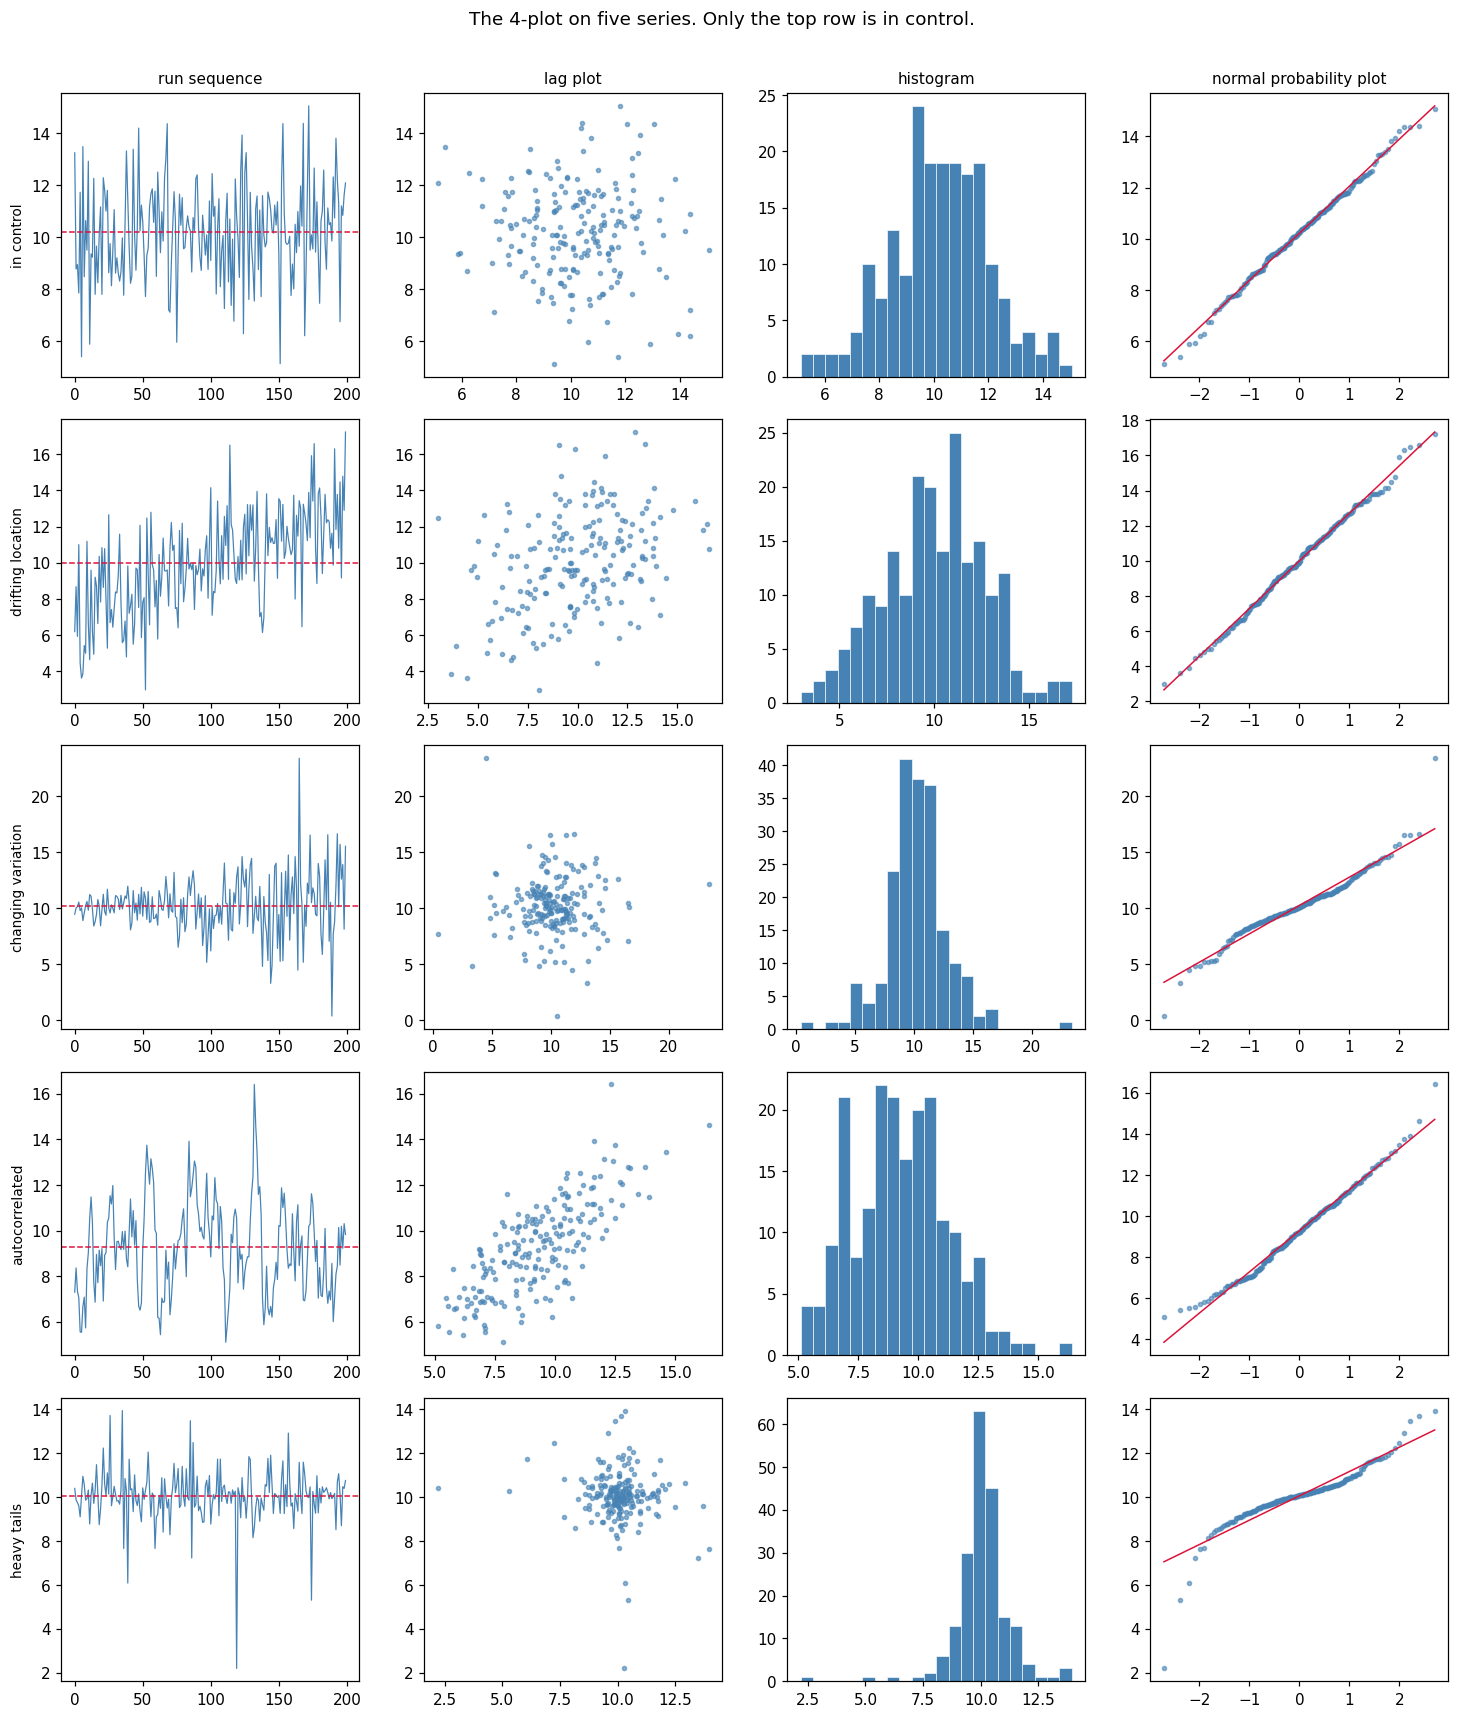

In [4]:
def four_plot(y, title, fig=None, row=0, nrows=1):
    """The NIST 4-plot: run sequence, lag, histogram, normal probability."""
    if fig is None:
        fig = plt.figure(figsize=(13, 3.1))
    ax = fig.add_subplot(nrows, 4, row*4 + 1)
    ax.plot(y, lw=.8, color="steelblue")
    ax.axhline(y.mean(), color="crimson", lw=1, ls="--")
    ax.set_ylabel(title, fontsize=9)
    if row == 0: ax.set_title("run sequence", fontsize=10)

    ax = fig.add_subplot(nrows, 4, row*4 + 2)
    ax.scatter(y[:-1], y[1:], s=7, alpha=.6, color="steelblue")
    if row == 0: ax.set_title("lag plot", fontsize=10)

    ax = fig.add_subplot(nrows, 4, row*4 + 3)
    ax.hist(y, bins=22, color="steelblue", edgecolor="white", linewidth=.4)
    if row == 0: ax.set_title("histogram", fontsize=10)

    ax = fig.add_subplot(nrows, 4, row*4 + 4)
    m = len(y)
    ppx = st.norm.ppf((np.arange(1, m+1) - 0.3175) / (m + 0.365))
    ys = np.sort(y)
    ax.scatter(ppx, ys, s=7, alpha=.6, color="steelblue")
    cf = np.polyfit(ppx, ys, 1)
    ax.plot(ppx, np.polyval(cf, ppx), color="crimson", lw=1)
    if row == 0: ax.set_title("normal probability plot", fontsize=10)
    return fig

fig = plt.figure(figsize=(13.5, 3.1*len(series)))
for r, (k, y) in enumerate(series.items()):
    four_plot(y, k, fig=fig, row=r, nrows=len(series))
fig.suptitle("The 4-plot on five series. Only the top row is in control.",
             fontsize=12, y=1.005)
plt.tight_layout(); plt.show()

## 3. What it costs to skip this

NIST is blunt about the stakes — non-randomness makes *"all of the usual
statistical tests invalid"* and renders *"calculated uncertainties for commonly
used statistics"* meaningless — but the handbook stops at the statement. It gives
no formula for how wrong.

So here is the number.

Take the most basic inferential act there is: computing a 95% confidence interval
for a mean. The standard error $s/\sqrt{n}$ assumes independent draws. Under AR(1)
autocorrelation with parameter $\rho$, the true standard deviation of the sample
mean is inflated by approximately

$$\sqrt{\frac{1+\rho}{1-\rho}}$$

At $\rho = 0.8$ that is a factor of **3**. The interval is three times too narrow,
and a "95% confidence interval" stops containing the truth 95% of the time.

The experiment below runs 20,000 simulated series at each $\rho$, so the coverage
figures are measured rather than argued.

In [5]:
banner("WHAT A '95% CONFIDENCE INTERVAL' IS ACTUALLY WORTH")

rc = np.random.RandomState(0)
n_ci, TRIALS = 50, 20000

print(f"  n = {n_ci} observations per series, {TRIALS:,} series per row")
print(f"  true mean is 0; we ask how often the nominal 95% interval contains it")
print()
print(f"  {'rho':>5}  {'true sd(mean)':>14}  {'naive SE':>10}  {'observed':>9}"
      f"  {'theory':>8}  {'95% coverage':>13}")
print("  " + "-" * 70)

cov_rows = []
for rho_ in [0.0, 0.3, 0.6, 0.8, 0.9]:
    means, ses, hit = [], [], 0
    for _ in range(TRIALS):
        e_ = rc.standard_normal(n_ci)
        x_ = np.empty(n_ci)
        x_[0] = e_[0] / np.sqrt(1 - rho_**2) if rho_ else e_[0]
        for i in range(1, n_ci):
            x_[i] = rho_*x_[i-1] + e_[i]
        m_ = x_.mean(); se_ = x_.std(ddof=1) / np.sqrt(n_ci)
        means.append(m_); ses.append(se_)
        hit += abs(m_) <= 1.96*se_
    means, ses = np.array(means), np.array(ses)
    obs = means.std() / ses.mean()
    th  = np.sqrt((1+rho_)/(1-rho_))
    cov_rows.append((rho_, hit/TRIALS, obs, th))
    print(f"  {rho_:>5.1f}  {means.std():>14.4f}  {ses.mean():>10.4f}"
          f"  {obs:>9.3f}  {th:>8.3f}  {hit/TRIALS:>12.1%}")
print("  " + "-" * 70)

step("Read the last two columns together")
print(f"  observed inflation tracks sqrt((1+rho)/(1-rho)) closely:")
for rho_, cv, obs, th in cov_rows:
    print(f"    rho = {rho_:.1f}:  observed {obs:.3f}  vs theory {th:.3f}"
          f"   (gap {abs(obs-th):.3f})")
print(f"  The formula is asymptotic in n, so the gap widens at rho = 0.9 where")
print(f"  n = {n_ci} is no longer large relative to the correlation length.")

step("And the consequence")
c0 = [r for r in cov_rows if r[0] == 0.0][0]
c8 = [r for r in cov_rows if r[0] == 0.8][0]
print(f"  independent data     : nominal 95%, actual {c0[1]:.1%}   -- as advertised")
print(f"  rho = 0.8            : nominal 95%, actual {c8[1]:.1%}   -- worse than a coin flip")
print()
print(f"  Nothing about the data looks wrong. The mean is right, the standard")
print(f"  deviation is right, the histogram is bell-shaped, the normal")
print(f"  probability plot is straight. The ONLY symptom is in the lag plot,")
print(f"  and the price for not looking is an interval that is wrong more often")
print(f"  than it is right.")
print()
print(f"  This is what NIST means by 'the usual statistical tests become")
print(f"  invalid'. It is not a caution -- {(0.95-c8[1])/0.95:.0%} of the reliability you thought")
print(f"  you had is simply gone, and nothing in the output announces it.")

  WHAT A '95% CONFIDENCE INTERVAL' IS ACTUALLY WORTH
  n = 50 observations per series, 20,000 series per row
  true mean is 0; we ask how often the nominal 95% interval contains it

    rho   true sd(mean)    naive SE   observed    theory   95% coverage
  ----------------------------------------------------------------------
    0.0          0.1405      0.1407      0.998     1.000         94.6%
    0.3          0.1999      0.1460      1.370     1.363         84.0%
    0.6          0.3473      0.1697      2.047     2.000         65.6%
    0.8          0.6731      0.2135      3.152     3.000         46.5%
    0.9          1.2716      0.2645      4.807     4.359         31.6%
  ----------------------------------------------------------------------

Read the last two columns together
  observed inflation tracks sqrt((1+rho)/(1-rho)) closely:
    rho = 0.0:  observed 0.998  vs theory 1.000   (gap 0.002)
    rho = 0.3:  observed 1.370  vs theory 1.363   (gap 0.007)
    rho = 0.6:  observed 2

## 4. Why graphics come first: Anscombe's quartet

The handbook devotes a section to the role of graphics. The classic demonstration
is Anscombe's quartet — four data sets agreeing on essentially every summary
statistic anyone routinely computes, and looking nothing alike.

It is worth reproducing exactly because the agreement is not approximate.

In [6]:
banner("FOUR DATA SETS, ONE SET OF SUMMARY STATISTICS")

ax_ = np.array([10,8,13,9,11,14,6,4,12,7,5], float)
ay1 = np.array([8.04,6.95,7.58,8.81,8.33,9.96,7.24,4.26,10.84,4.82,5.68])
ay2 = np.array([9.14,8.14,8.74,8.77,9.26,8.10,6.13,3.10,9.13,7.26,4.74])
ay3 = np.array([7.46,6.77,12.74,7.11,7.81,8.84,6.08,5.39,8.15,6.42,5.73])
ax4 = np.array([8,8,8,8,8,8,8,19,8,8,8], float)
ay4 = np.array([6.58,5.76,7.71,8.84,8.47,7.04,5.25,12.50,5.56,7.91,6.89])

quartet = [("I", ax_, ay1), ("II", ax_, ay2), ("III", ax_, ay3), ("IV", ax4, ay4)]

print(f"  {'set':>5}  {'mean x':>8}  {'var x':>8}  {'mean y':>8}  {'var y':>8}"
      f"  {'corr':>7}  {'slope':>7}  {'intercept':>10}")
print("  " + "-" * 72)
for nm, xq, yq in quartet:
    sl, ic = np.polyfit(xq, yq, 1)
    print(f"  {nm:>5}  {xq.mean():>8.4f}  {xq.var(ddof=1):>8.4f}  {yq.mean():>8.4f}"
          f"  {yq.var(ddof=1):>8.4f}  {np.corrcoef(xq,yq)[0,1]:>7.4f}"
          f"  {sl:>7.4f}  {ic:>10.4f}")
print("  " + "-" * 72)

step("How close is 'identical'?")
for lab, vals in [
        ("mean x",    [q[1].mean() for q in quartet]),
        ("var x",     [q[1].var(ddof=1) for q in quartet]),
        ("mean y",    [q[2].mean() for q in quartet]),
        ("var y",     [q[2].var(ddof=1) for q in quartet]),
        ("corr",      [np.corrcoef(q[1],q[2])[0,1] for q in quartet]),
        ("slope",     [np.polyfit(q[1],q[2],1)[0] for q in quartet])]:
    print(f"  {lab:>8}: spread across the four sets = {max(vals)-min(vals):.4f}")
print()
print("  Every routine summary agrees to two or three decimals. A table of")
print("  these numbers gives no hint that the four data sets differ at all.")

step("What the plots show")
for nm, xq, yq in quartet:
    lag = "linear with scatter" if nm == "I" else \
          "a clean parabola -- the wrong model entirely" if nm == "II" else \
          "perfectly linear except one outlier" if nm == "III" else \
          "one x value plus a single leverage point holding the whole fit"
    print(f"  set {nm:>3}: {lag}")
print()
print("  Set IV is the sharpest: ten points share one x value, so the slope is")
print("  determined entirely by the eleventh. Remove it and the fit is")
print("  undefined. No summary statistic in the table above says so.")

  FOUR DATA SETS, ONE SET OF SUMMARY STATISTICS
    set    mean x     var x    mean y     var y     corr    slope   intercept
  ------------------------------------------------------------------------
      I    9.0000   11.0000    7.5009    4.1273   0.8164   0.5001      3.0001
     II    9.0000   11.0000    7.5009    4.1276   0.8162   0.5000      3.0009
    III    9.0000   11.0000    7.5000    4.1226   0.8163   0.4997      3.0025
     IV    9.0000   11.0000    7.5009    4.1232   0.8165   0.4999      3.0017
  ------------------------------------------------------------------------

How close is 'identical'?
    mean x: spread across the four sets = 0.0000
     var x: spread across the four sets = 0.0000
    mean y: spread across the four sets = 0.0009
     var y: spread across the four sets = 0.0050
      corr: spread across the four sets = 0.0003
     slope: spread across the four sets = 0.0004

  Every routine summary agrees to two or three decimals. A table of
  these numbers gives 

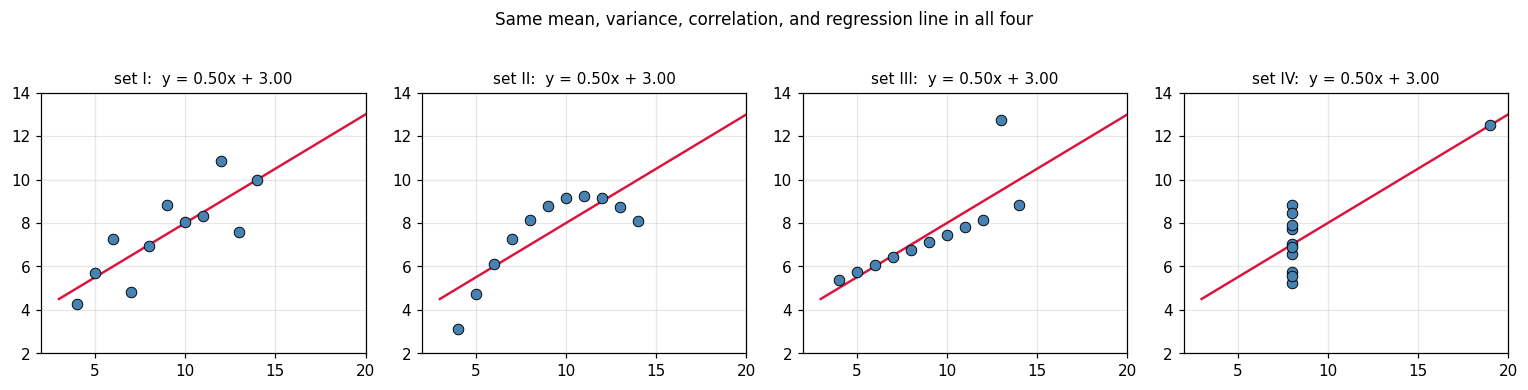

In [7]:
fig, axes = plt.subplots(1, 4, figsize=(14, 3.4))
xr = np.linspace(3, 20, 50)
for ax, (nm, xq, yq) in zip(axes, quartet):
    sl, ic = np.polyfit(xq, yq, 1)
    ax.scatter(xq, yq, s=48, color="steelblue", edgecolor="k", linewidths=.6,
               zorder=3)
    ax.plot(xr, sl*xr + ic, color="crimson", lw=1.6)
    ax.set_title(f"set {nm}:  y = {sl:.2f}x + {ic:.2f}", fontsize=10)
    ax.set_xlim(2, 20); ax.set_ylim(2, 14); ax.grid(alpha=.3)
fig.suptitle("Same mean, variance, correlation, and regression line in all four",
             fontsize=11, y=1.03)
plt.tight_layout(); plt.show()

## 5. What to take away

**EDA is a stance, not a checklist.** NIST's framing is that it *postpones* the
model rather than assuming one and testing it afterwards. The techniques follow
from that; the order of operations is the substance.

**Four assumptions sit under almost everything you will compute**: random
drawings, from a fixed distribution, with fixed location and fixed variation.
They are the conditions under which a mean, a standard error, and a $p$-value
mean what they claim.

**The 4-plot checks all four in one figure**, and it is diagnostic rather than
merely descriptive — the panel that fails names the assumption that failed. Run
sequence for location and variation, lag plot for randomness, histogram and
normal probability plot for the distribution.

**The lag plot is the one to stop skipping.** In the autocorrelated series above,
the mean was right, the standard deviation was right, the histogram was
bell-shaped and the probability plot was straight. Every summary passed. Only the
ordering carried the defect — and the cost was a 95% confidence interval that
contained the truth 47% of the time.

**Look at the data before summarising it.** Anscombe's quartet agrees on mean,
variance, correlation and regression line to three decimals across four data sets
that share no shape at all.

### Verified in this notebook

- The 4-plot built panel by panel, with the lag plot's correlation shown to be the lag-1 autocorrelation and the probability plot reduced to a PPCC
- Five series where four are broken: the mean and standard deviation flag none of them, and each broken one is caught by a different panel
- The autocorrelated series passing drift, spread and normality checks while failing only the lag plot
- Confidence-interval coverage measured over 20,000 simulations per $\rho$, falling from 94.6% to 46.5%, with the observed inflation matching $\sqrt{(1+\rho)/(1-\rho)}$
- Anscombe's quartet reproduced, with the spread of every summary statistic across the four sets printed

### Where this connects

This page comes before all the others. [[cross-validation]] assumes your rows are
independent draws — the lag plot is how you find out they are not, and
`GroupKFold` is what you do about it. [[data-leakage]] is the same failure
arriving through a different door. [[evaluation-metrics]] computes numbers that
only mean something once these assumptions hold, and
[[how-models-learn-the-concepts]] is where the modelling starts.

### Source

NIST/SEMATECH, *e-Handbook of Statistical Methods*, chapter 1: [Exploratory Data
Analysis](https://www.itl.nist.gov/div898/handbook/eda/eda.htm). The four
assumptions, the 4-plot and its interpretation, and the seven goals are the
handbook's. Section 3 goes beyond it: NIST states that non-randomness invalidates
the usual tests without quantifying it, and the coverage experiment supplies the
missing number.